# Field Safety Monitoring with Real Crash Reports

**Module 07 · Runtime Assurance and Operations** · Notebook 5 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/07_Runtime_Assurance_and_Operations/05_field_safety_monitoring.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [ODD and runtime monitoring](01_odd_and_runtime_monitoring.ipynb) (SPIs), [Statistical safety validation](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb), [Incident case studies](../02_Failures_and_Robustness/01_incident_case_studies.ipynb) | NHTSA SGO 2021-01 (third amendment), UL 4600 (3rd ed., 2023), ISO/TS 5083:2025, UN R157, UN R155, Regulation (EU) 2022/1426 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After this notebook you will be able to:

- state what the NHTSA Standing General Order (SGO) requires to be reported for ADS and for Level 2 ADAS under the third amendment, and why the two populations have different reporting thresholds;
- load the public SGO crash reports, resolve report versions and duplicate reports of the same crash, and handle redactions (CBI, PII);
- describe the ADS and ADAS crash populations by operator, state, roadway, crash partner, pre-crash movement, injury severity and time, and say what the two populations can and cannot be compared on;
- turn reports into rates using an operator's published, dated exposure (Waymo Safety Impact Data Hub), with exact Poisson confidence intervals, and show why a human benchmark must be matched by geography and outcome definition;
- build a small safety performance indicator (SPI) dashboard with leading and lagging indicators in the sense of UL 4600;
- extract simple themes from unredacted crash narratives, and name the main biases of field crash data;
- place field monitoring in the regulatory frame (UN R157, UN R155, EU 2022/1426, ISO/TS 5083) and in an incident escalation process.

> **How to read the numbers.** All counts below are computed from the files as downloaded when the notebook runs. The NHTSA files are updated monthly, so your counts may differ from the stored outputs; the stored run used the release of **15 October 2026** (reports received through 15 September 2026).

## Setup

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D
from avsafety.validation import poisson_rate_interval

import re
import urllib.error
import urllib.parse
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

rng = np.random.default_rng(42)          # only used to pick example narratives
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
# Okabe-Ito colour-blind-safe palette
OI = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
      "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "black": "#000000", "grey": "#999999"}
pd.set_option("display.max_colwidth", 120)
print("avsafety", avsafety.__version__ if hasattr(avsafety, "__version__") else "", "| pandas", pd.__version__)

avsafety 1.1.0 | pandas 3.1.0


### Data and licence

- **NHTSA SGO crash reports** (ADS and Level 2 ADAS files), loaded with `avsafety.data.nhtsa_sgo`. Public US government data.
- **Waymo Safety Impact Data Hub**, data through June 2026 (release of 2 October 2026): the list of rider-only crashes with their SGO report IDs (CSV2) and the human benchmarks (CSV3). Waymo publishes these files "to help researchers reproduce the results or conduct their own research" (Data Hub release notes). The cumulative rider-only miles per area (CSV1) are small enough to be written into the notebook, each value with its release date.

In [2]:
print(D.attribution("NHTSA SGO"))
print("Data: Waymo Safety Impact Data Hub (data through June 2026), https://waymo.com/safety/impact/")

Data: NHTSA Standing General Order 2021-01 crash reports, public US government data, https://www.nhtsa.gov/laws-regulations/standing-general-order-crash-reporting
Data: Waymo Safety Impact Data Hub (data through June 2026), https://waymo.com/safety/impact/


---
## 1. The Standing General Order: what must be reported

NHTSA issued **Standing General Order 2021-01** on 29 June 2021 under its information-gathering authority (49 U.S.C. 30166(g)). It requires the manufacturers and operators named in the order to report crashes of vehicles equipped with an **automated driving system (ADS)** or a **Level 2 ADAS**, on publicly accessible US roads, when the system was engaged at any time from **30 seconds before the crash** until its end. The order was amended on 5 August 2021, 5 April 2023 and — the version in force — on **24 April 2025 (third amendment, effective 16 June 2025)** (91 FR 48485; 91 FR 30789).

Reporting under the third amendment, as summarised by NHTSA in its May 2026 information-collection notice (91 FR 30789):

| Request | ADS | Level 2 ADAS | Deadline |
|---|---|---|---|
| **No. 1** — most severe crashes | fatality, anyone transported to a hospital for treatment, air-bag deployment, strike of a vulnerable road user (VRU), **or a vehicle tow-away** | fatality, hospital transport, air-bag deployment, VRU strike (no tow-away criterion) | initial report within **5 calendar days** of notice |
| **No. 2** — other crashes with property damage | crashes not meeting No. 1 where the damage is reasonably expected to exceed USD 1,000, the subject vehicle was the only vehicle involved, or the subject vehicle struck another vehicle or object | **not reported** | 15th day of the following month |
| **No. 3** — updates | materially new or different information in specified fields (e.g. engagement, severity, narrative) | same | 15th day of the following month |

Other changes of the third amendment: the one-day reporting track was removed (now five days), only one entity has to report a crash unless another holds materially different information, no "nil" monthly reports, and no periodic updates without new information.

Three definitions shape the data:

- **Crash**: "any physical impact between a vehicle and another road user … or property that results or allegedly results in any property damage, injury, or fatality"; the subject vehicle is *involved* if it impacts or "contributes or is alleged to contribute" to the impact. **Fault is not part of the definition.**
- **Notice**: information "from any internal or external source and in any form", including allegations — reports are filed "regardless of whether the manufacturer has verified those facts".
- **Redactions**: NHTSA publishes the reports monthly "with redactions for PII and information claimed to be CBI" (confidential business information). Reporting entities may claim CBI for some fields, notably the narrative, the automation-feature version and "Within ODD?".

Consequences for analysis — keep these in mind for every chart below:

1. **Reports ≠ crashes.** A crash can have several report versions (updates) and, rarely, reports by several entities (`Same Incident ID`).
2. **Crashes ≠ rates.** The SGO contains no exposure (miles, hours, trips). Counts grow with fleet size.
3. **ADS ≠ ADAS thresholds.** ADS operators report almost every contact; Level 2 ADAS manufacturers report only severe crashes, and only those they learn about (mostly via telematics).
4. **Allegation ≠ cause.** Narratives are the reporting entity's account; NHTSA's data dictionary warns that report data "may be incomplete or unverified".

---
## 2. Loading and cleaning the reports

In [3]:
raw = {kind: D.nhtsa_sgo(kind) for kind in ("ADS", "ADAS")}
for kind, df in raw.items():
    sub = pd.to_datetime(df["Report Submission Date"], format="%b-%Y")
    print(f"{kind:4s}: {len(df):5d} rows | {df['Report ID'].nunique():5d} report IDs | "
          f"{df['Same Incident ID'].nunique():5d} incident IDs | {df.shape[1]} columns | "
          f"submitted {sub.min():%b %Y} to {sub.max():%b %Y}")

ADS :  1595 rows |  1551 report IDs |  1552 incident IDs | 116 columns | submitted Jun 2025 to Sep 2026
ADAS:  2574 rows |  2427 report IDs |  2424 incident IDs | 116 columns | submitted Jun 2025 to Sep 2026


The current files start in June 2025: they hold the reports filed under the third amendment. Reports under earlier versions of the order (July 2021 to mid-June 2025) are published separately in NHTSA's archive section and use partly different fields, so this notebook analyses only the third-amendment period.

**Cleaning steps.**

1. Keep the **latest version** of each `Report ID` (updates replace earlier versions).
2. Parse month fields; mark redacted values (`[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]`, `[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION]`, `[XXX]` inside narratives).
3. Derive analysis flags: injury level, hospital or fatal, air bag, tow-away, VRU crash partner, and the Request No. 1 criteria.
4. Collapse to **one row per crash** with `Same Incident ID`.

In [4]:
CBI = "[REDACTED, MAY CONTAIN CONFIDENTIAL BUSINESS INFORMATION]"
PII = "[MAY CONTAIN PERSONALLY IDENTIFIABLE INFORMATION]"
SEVERITY = {  # ordinal scale used for plotting (higher = worse); 'Unknown' kept separate
    "Property Damage. No Injured Reported": 0, "No Injured Reported": 0,
    "Minor W/O Hospitalization": 1, "Minor W/ Hospitalization": 2,
    "Moderate W/O Hospitalization": 3, "Moderate W/ Hospitalization": 4,
    "Serious W/O Hospitalization": 5, "Serious W/ Hospitalization": 6, "Fatality": 7}
SEV_GROUP = {0: "no injury reported", 1: "minor", 2: "minor", 3: "moderate", 4: "moderate",
             5: "serious", 6: "serious", 7: "fatal"}
MOVING = {"Proceeding Straight", "Making Left Turn", "Making Right Turn", "Changing Lanes", "Passing",
          "Merging", "Entering Traffic", "Making U-Turn", "Lane / Road Departure", "Backing", "Parking Maneuver"}


def short_name(entity: str) -> str:
    s = re.sub(r",? ?(Inc\.?|LLC|Corp\.?|Corporation|Operations|America|USA|Company|of North America)\b", "", str(entity))
    return re.sub(r"\s+", " ", s).strip(" ,.")


def clean(df: pd.DataFrame, kind: str) -> pd.DataFrame:
    d = df.sort_values("Report Version").groupby("Report ID").tail(1).copy()     # latest version
    d["kind"] = kind
    d["operator"] = d["Reporting Entity"].map(short_name)
    d["incident_month"] = pd.to_datetime(d["Incident Date"], format="%b-%Y")
    d["submitted_month"] = pd.to_datetime(d["Report Submission Date"], format="%b-%Y")
    d["severity"] = d["Highest Injury Severity Alleged"].map(SEVERITY)          # NaN = Unknown
    d["severity_group"] = d["severity"].map(SEV_GROUP).fillna("unknown")
    d["hospital_or_fatal"] = d["Highest Injury Severity Alleged"].str.contains("W/ Hosp|Fatality", na=False)
    d["airbag"] = d["Any Air Bags Deployed?"].str.contains("Yes", na=False)
    d["towed"] = d["Was Any Vehicle Towed?"].str.contains("Yes", na=False)
    d["vru"] = d["Crash With"].str.startswith("Non-Motorist", na=False)
    d["request1"] = d["hospital_or_fatal"] | d["airbag"] | d["vru"] | (d["towed"] & (kind == "ADS"))
    d["sv_moving"] = d["SV Pre-Crash Movement"].isin(MOVING)
    d["narrative_cbi"] = d["Narrative - CBI?"].eq("Y") | d["Narrative"].eq(CBI)
    d["odd_cbi"] = d["Within ODD?"].eq(CBI)
    d["telematics"] = d["Source - Telematics"].eq("Y")
    return d


reports = {k: clean(v, k) for k, v in raw.items()}
crashes = {k: v.sort_values(["Report ID"]).drop_duplicates("Same Incident ID") for k, v in reports.items()}

rows = []
for k in ("ADS", "ADAS"):
    r, c = reports[k], crashes[k]
    multi = r.groupby("Same Incident ID")["Report ID"].nunique()
    rows.append({"population": k, "rows (all versions)": len(raw[k]), "reports (latest version)": len(r),
                 "crashes (unique incident)": len(c), "crashes with >1 report": int((multi > 1).sum()),
                 "narrative CBI-redacted [%]": round(100 * r["narrative_cbi"].mean(), 1),
                 "'Within ODD?' CBI-redacted [%]": round(100 * r["odd_cbi"].mean(), 1),
                 "notice via telematics [%]": round(100 * r["telematics"].mean(), 1)})
cleaning = pd.DataFrame(rows).set_index("population")
display(cleaning)

,rows (all versions),reports (latest version),crashes (unique incident),crashes with >1 report,narrative CBI-redacted [%],'Within ODD?' CBI-redacted [%],notice via telematics [%]
population,,,,,,,
ADS,1595,1551,1550,1,0.6,1.0,88.5
ADAS,2574,2427,2418,7,91.2,90.9,89.3


In [5]:
# Sanity check against NHTSA's own figure: "From [June 2025] through the end of 2025, NHTSA received reports of
# 517 alleged crashes involving ADS and 787 alleged crashes involving Level 2 ADAS" (91 FR 48485, 31 Jul 2026).
for k, nhtsa in (("ADS", 517), ("ADAS", 787)):
    v1 = raw[k].sort_values("Report Version").groupby("Report ID").head(1)          # first version = date received
    received = v1[pd.to_datetime(v1["Report Submission Date"], format="%b-%Y") <= "2025-12-31"]
    by_incident = crashes[k][(crashes[k]["incident_month"] >= "2025-06-01") & (crashes[k]["incident_month"] <= "2025-12-31")]
    print(f"{k:4s}: NHTSA {nhtsa} | first reports received Jun-Dec 2025: {received['Same Incident ID'].nunique()} "
          f"| crashes with incident month Jun-Dec 2025 (as of this release): {len(by_incident)}")
print("The counts differ with the cut (date received vs. incident date), with later-filed reports and with how")
print("NHTSA counted at the time. Always state which cut a number uses.")

ADS : NHTSA 517 | first reports received Jun-Dec 2025: 506 | crashes with incident month Jun-Dec 2025 (as of this release): 571
ADAS: NHTSA 787 | first reports received Jun-Dec 2025: 730 | crashes with incident month Jun-Dec 2025 (as of this release): 749
The counts differ with the cut (date received vs. incident date), with later-filed reports and with how
NHTSA counted at the time. Always state which cut a number uses.


**Consistency check of the reporting tracks.** The report type chosen by the reporting entity should agree with the Request No. 1 criteria derived from the fields. Disagreements are not necessarily errors — an injury may only become known after a monthly report was filed — but they are exactly what a data-quality review looks at.

In [6]:
for k in ("ADS", "ADAS"):
    tab = pd.crosstab(reports[k]["Report Type"], reports[k]["request1"].map({True: "meets Request 1 criteria",
                                                                            False: "does not"}))
    print(k); display(tab)
a = reports["ADS"]
n_5day_no = int(((a["Report Type"] == "5-Day") & ~a["request1"]).sum())
n_month_yes = int(((a["Report Type"] == "Monthly") & a["request1"]).sum())
print(f"ADS: {n_5day_no} five-day reports without a derivable Request 1 criterion; "
      f"{n_month_yes} monthly reports that meet one (e.g. injury or tow-away learned later, or coding differences).")

ADS


request1,does not,meets Request 1 criteria
Report Type,,
5-Day,16,768
Monthly,705,26
Update,22,14


ADAS


request1,does not,meets Request 1 criteria
Report Type,,
5-Day,22,2235
Monthly,2,2
Update,14,152


ADS: 16 five-day reports without a derivable Request 1 criterion; 26 monthly reports that meet one (e.g. injury or tow-away learned later, or coding differences).


---
## 3. Descriptive analysis of ADS crashes

One row per crash (unique `Same Incident ID`). Remember that the operator panel mostly shows **fleet size**, not safety: Waymo operates by far the largest driverless fleet, so it files most reports.

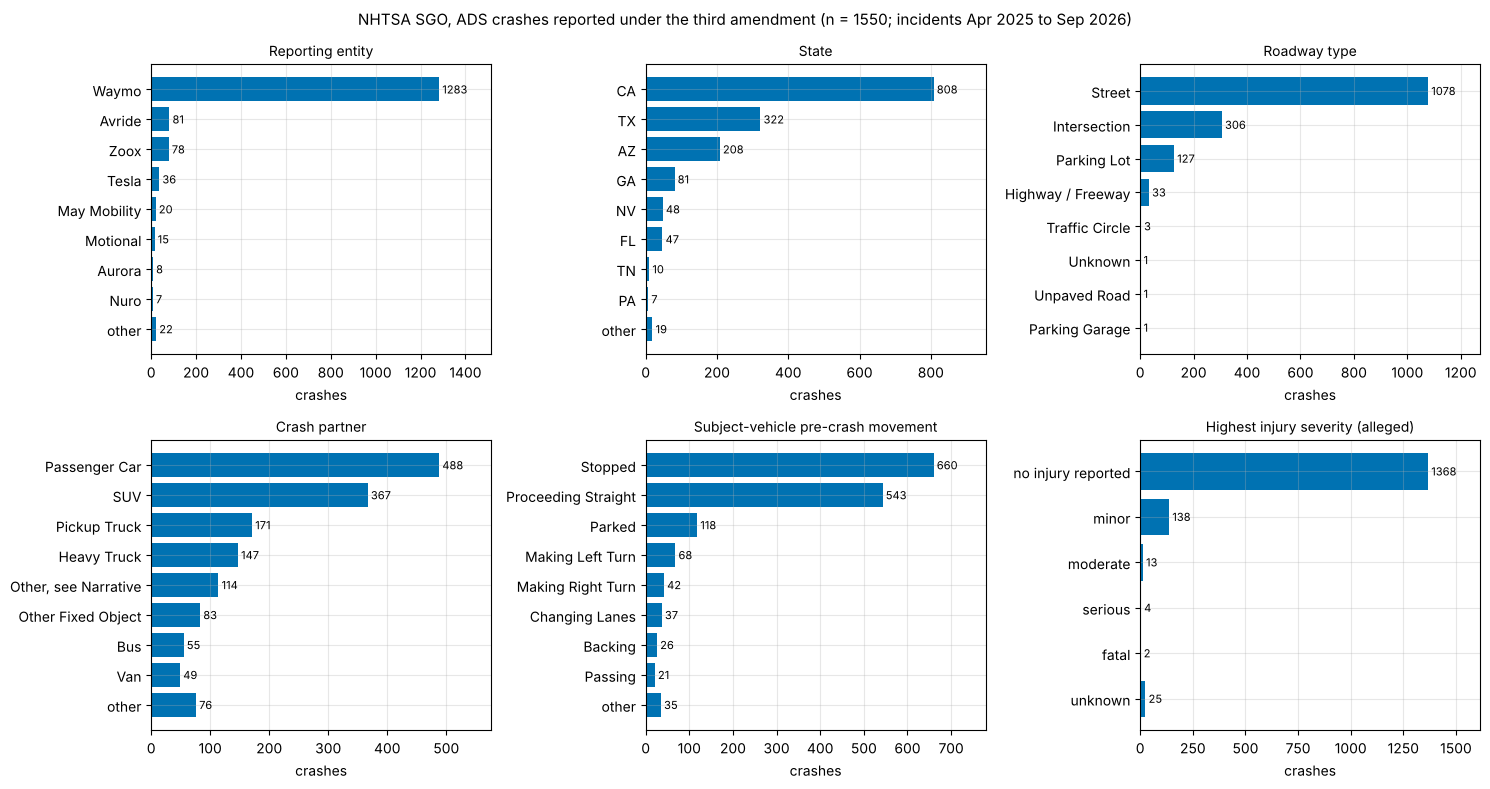

In [7]:
ads = crashes["ADS"]


def top(series, n=8, other="other"):
    vc = series.fillna("missing").value_counts()
    return pd.concat([vc.iloc[:n], pd.Series({other: vc.iloc[n:].sum()})]) if len(vc) > n else vc


panels = [("operator", "Reporting entity", ads["operator"]),
          ("state", "State", ads["State"]),
          ("road", "Roadway type", ads["Roadway Type"]),
          ("partner", "Crash partner", ads["Crash With"]),
          ("movement", "Subject-vehicle pre-crash movement", ads["SV Pre-Crash Movement"]),
          ("severity", "Highest injury severity (alleged)", ads["severity_group"])]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (_, title, s) in zip(axes.flat, panels):
    vc = top(s)
    if title.startswith("Highest"):
        vc = s.value_counts().reindex(["no injury reported", "minor", "moderate", "serious", "fatal", "unknown"]).dropna()
    ax.barh(vc.index[::-1].astype(str), vc.values[::-1], color=OI["blue"])
    ax.set_title(title, fontsize=10); ax.set_xlabel("crashes")
    for y, v in enumerate(vc.values[::-1]):
        ax.text(v, y, f" {int(v)}", va="center", fontsize=8)
    ax.set_xlim(0, vc.max() * 1.18)
fig.suptitle(f"NHTSA SGO, ADS crashes reported under the third amendment (n = {len(ads)}; "
             f"incidents {ads['incident_month'].min():%b %Y} to {ads['incident_month'].max():%b %Y})", fontsize=11)
plt.tight_layout(); plt.show()

In [8]:
share = lambda m: 100 * m.mean()
stopped = ads["SV Pre-Crash Movement"].isin(["Stopped", "Parked"])
print("Text summary (computed from the ADS crashes above):")
print(f"- {len(ads)} crashes from {ads['operator'].nunique()} reporting entities; the largest, "
      f"{ads['operator'].value_counts().index[0]}, accounts for {share(ads['operator'].eq(ads['operator'].value_counts().index[0])):.0f} %.")
print(f"- Top states: {', '.join(f'{s} ({n})' for s, n in ads['State'].value_counts().head(4).items())}.")
print(f"- {share(ads['Roadway Type'].eq('Highway / Freeway')):.1f} % on highways/freeways; "
      f"{share(ads['Roadway Type'].isin(['Street', 'Intersection'])):.0f} % on streets or at intersections.")
print(f"- The ADS vehicle was stopped or parked in {share(stopped):.0f} % of crashes "
      f"(moving in {share(ads['sv_moving']):.0f} %).")
print(f"- VRU crash partner in {int(ads['vru'].sum())} crashes; "
      f"hospital-level or fatal outcome alleged in {int(ads['hospital_or_fatal'].sum())} "
      f"({int(ads['Highest Injury Severity Alleged'].eq('Fatality').sum())} fatal).")
print("A stopped ADS vehicle being struck is common in urban robotaxi data; it does not by itself say who was at fault,")
print("and some of these crashes may still involve ADS behaviour (e.g. an unexpected stop).")

Text summary (computed from the ADS crashes above):
- 1550 crashes from 18 reporting entities; the largest, Waymo, accounts for 83 %.
- Top states: CA (808), TX (322), AZ (208), GA (81).
- 2.1 % on highways/freeways; 89 % on streets or at intersections.
- The ADS vehicle was stopped or parked in 50 % of crashes (moving in 49 %).
- VRU crash partner in 26 crashes; hospital-level or fatal outcome alleged in 54 (2 fatal).
A stopped ADS vehicle being struck is common in urban robotaxi data; it does not by itself say who was at fault,
and some of these crashes may still involve ADS behaviour (e.g. an unexpected stop).


### 3.1 Time trend — and why it is not a safety trend

Monthly crash counts by incident month. Two artefacts must be marked before anyone reads a trend into the curve: the first month is partial (the amendment took effect on 16 June 2025), and the most recent months are incomplete because monthly (Request No. 2) reports arrive up to six weeks later and updates later still.

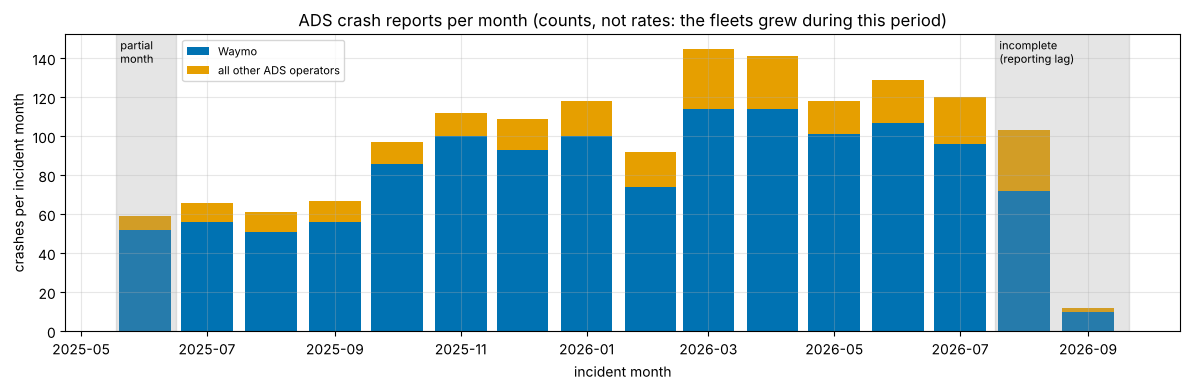

Complete months Jul 2025 to Jul 2026: 61 to 145 crashes per month (median 112).


In [9]:
monthly = (ads.assign(group=np.where(ads["operator"].str.startswith("Waymo"), "Waymo", "all other ADS operators"))
              .groupby(["incident_month", "group"]).size().unstack(fill_value=0))
monthly = monthly.loc["2025-06-01":]
last_release = raw["ADS"]["Report Submission Date"].pipe(pd.to_datetime, format="%b-%Y").max()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(monthly.index, monthly["Waymo"], width=25, color=OI["blue"], label="Waymo")
ax.bar(monthly.index, monthly["all other ADS operators"], width=25, bottom=monthly["Waymo"],
       color=OI["orange"], label="all other ADS operators")
ax.axvspan(pd.Timestamp("2025-05-18"), pd.Timestamp("2025-06-16"), color=OI["grey"], alpha=0.25)
ax.axvspan(last_release - pd.Timedelta(days=45), last_release + pd.Timedelta(days=20), color=OI["grey"], alpha=0.25)
ax.text(pd.Timestamp("2025-05-20"), monthly.sum(axis=1).max() * 0.95, "partial\nmonth", fontsize=8)
ax.text(last_release - pd.Timedelta(days=43), monthly.sum(axis=1).max() * 0.95, "incomplete\n(reporting lag)", fontsize=8)
ax.set_ylabel("crashes per incident month"); ax.set_xlabel("incident month")
ax.set_title("ADS crash reports per month (counts, not rates: the fleets grew during this period)")
ax.legend(loc="upper left", bbox_to_anchor=(0.1, 1.0), fontsize=8); plt.tight_layout(); plt.show()
complete = monthly.loc["2025-07-01":last_release - pd.DateOffset(months=2)].sum(axis=1)
print(f"Complete months Jul 2025 to {complete.index.max():%b %Y}: {complete.min()} to {complete.max()} crashes per month "
      f"(median {complete.median():.0f}).")

---
## 4. ADS versus Level 2 ADAS: what can be compared?

The two files look alike but describe **different populations under different rules**:

| Aspect | ADS file | Level 2 ADAS file |
|---|---|---|
| Who drives | the ADS (driverless or with a test driver) | a human driver, supported by ADAS |
| Reportable crashes | almost all (Requests 1 and 2) | severe only (Request 1, no tow-away) |
| Notice | mostly the operator's own fleet data | depends on what the manufacturer learns — mainly telematics (air-bag deployment) |
| Redactions | few | many: narratives and "Within ODD?" largely CBI for some manufacturers |
| Exposure | published by some operators | not published per system |

A **like-for-like** comparison is possible only on the subset that both populations must report: crashes with a fatality, hospital transport, air-bag deployment or VRU strike. Even then the comparison is of **composition** (which road types, which partners), not of risk, and it is distorted by the ADAS manufacturers' unequal access to crash information.

{'ADS': 137, 'ADAS': 2380} crashes meeting the criteria common to both orders


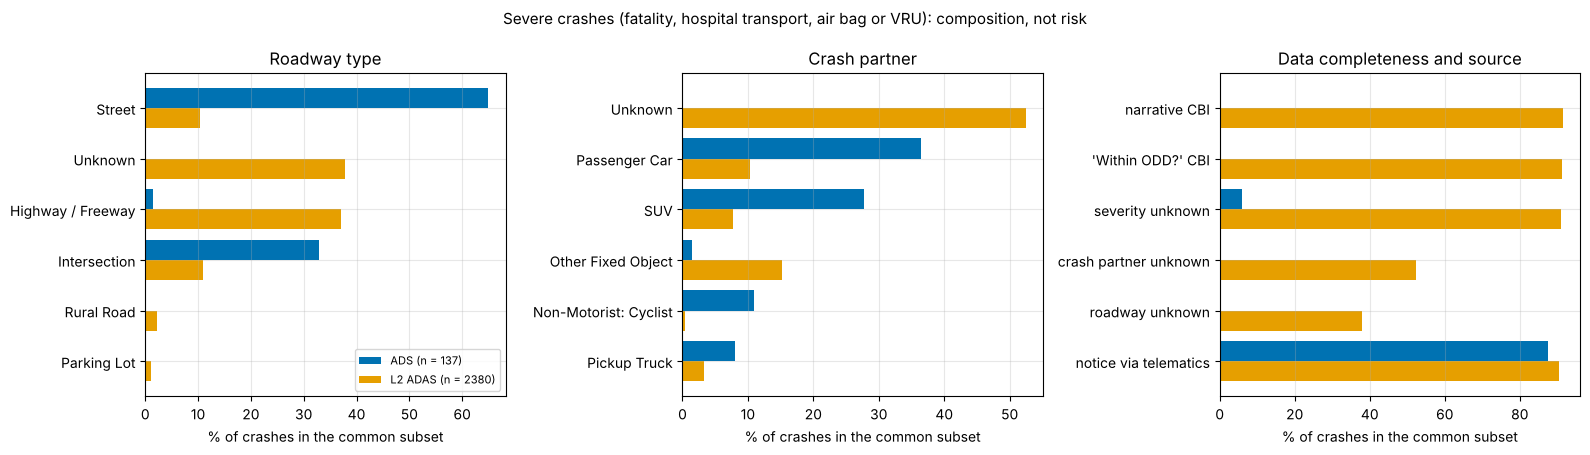

,ADS,ADAS
narrative CBI,0.0,91.5
'Within ODD?' CBI,0.0,91.3
severity unknown,5.8,91.0
crash partner unknown,0.0,52.4
roadway unknown,0.0,37.8
notice via telematics,87.6,90.4


In [10]:
common = {k: v[v["hospital_or_fatal"] | v["airbag"] | v["vru"]] for k, v in crashes.items()}
print({k: len(v) for k, v in common.items()}, "crashes meeting the criteria common to both orders")


def comp(col, mapper=None, keep=6):
    out = {}
    for k, v in common.items():
        s = v[col].map(mapper) if mapper else v[col]
        out[k] = s.fillna("missing").value_counts(normalize=True) * 100
    df = pd.DataFrame(out).fillna(0)
    return df.loc[df.max(axis=1).sort_values(ascending=False).index[:keep]]


road = comp("Roadway Type")
partner = comp("Crash With")
redaction = pd.DataFrame({k: {"narrative CBI": 100 * v["narrative_cbi"].mean(),
                              "'Within ODD?' CBI": 100 * v["odd_cbi"].mean(),
                              "severity unknown": 100 * v["severity"].isna().mean(),
                              "crash partner unknown": 100 * v["Crash With"].eq("Unknown").mean(),
                              "roadway unknown": 100 * v["Roadway Type"].eq("Unknown").mean(),
                              "notice via telematics": 100 * v["telematics"].mean()} for k, v in common.items()})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, df, title in [(axes[0], road, "Roadway type"), (axes[1], partner, "Crash partner"),
                      (axes[2], redaction, "Data completeness and source")]:
    y = np.arange(len(df))
    ax.barh(y - 0.2, df["ADS"], height=0.4, color=OI["blue"], label=f"ADS (n = {len(common['ADS'])})")
    ax.barh(y + 0.2, df["ADAS"], height=0.4, color=OI["orange"], label=f"L2 ADAS (n = {len(common['ADAS'])})")
    ax.set_yticks(y, df.index); ax.invert_yaxis(); ax.set_xlabel("% of crashes in the common subset"); ax.set_title(title)
axes[0].legend(fontsize=8)
fig.suptitle("Severe crashes (fatality, hospital transport, air bag or VRU): composition, not risk", fontsize=11)
plt.tight_layout(); plt.show()
display(redaction.round(1))

In [11]:
ad = crashes["ADAS"]
tes = ad["operator"].str.startswith("Tesla")
print("Text summary (computed):")
print(f"- In the common severe subset, highways/freeways account for {road.loc['Highway / Freeway', 'ADAS']:.0f} % of ADAS crashes "
      f"but {road.loc['Highway / Freeway', 'ADS']:.0f} % of ADS crashes: the systems operate on different roads.")
print(f"- {redaction.loc['severity unknown', 'ADAS']:.0f} % of severe ADAS crashes have unknown injury severity and "
      f"{redaction.loc['crash partner unknown', 'ADAS']:.0f} % an unknown crash partner (ADS: "
      f"{redaction.loc['severity unknown', 'ADS']:.0f} % and {redaction.loc['crash partner unknown', 'ADS']:.0f} %).")
print(f"- {100 * tes.mean():.0f} % of all ADAS crashes are reported by Tesla; {100 * ad.loc[tes, 'telematics'].mean():.0f} % of these "
      f"cite telematics as the source, versus {100 * ad.loc[~tes, 'telematics'].mean():.0f} % for the other manufacturers.")
print("A manufacturer with connected vehicles learns of more crashes, so it reports more: report counts partly measure")
print("data access, not safety. NHTSA states the same caveat: 'Access to crash data may affect crash reporting.'")

Text summary (computed):
- In the common severe subset, highways/freeways account for 37 % of ADAS crashes but 1 % of ADS crashes: the systems operate on different roads.
- 91 % of severe ADAS crashes have unknown injury severity and 52 % an unknown crash partner (ADS: 6 % and 0 %).
- 89 % of all ADAS crashes are reported by Tesla; 93 % of these cite telematics as the source, versus 63 % for the other manufacturers.
A manufacturer with connected vehicles learns of more crashes, so it reports more: report counts partly measure
data access, not safety. NHTSA states the same caveat: 'Access to crash data may affect crash reporting.'


**What can be compared** — composition of severe crashes (road type, partner, pre-crash movement) with explicit 'unknown' categories; reporting behaviour (timeliness, completeness, redaction) as a process indicator.

**What cannot** — rates or "which is safer": neither file carries exposure; the ADAS file covers only crashes the manufacturer heard about; the human driver remains responsible in Level 2; road types, speeds and ODDs differ.

---
## 5. The exposure problem: from reports to rates

A rate needs a numerator and a denominator that **refer to the same operation**. The SGO gives numerators only. Some operators publish exposure; the most detailed public example is the **Waymo Safety Impact Data Hub**, which lists, for each release, the cumulative **rider-only (RO)** miles per area (no human driver on board) and the RO crashes with their SGO report IDs.

### 5.1 Matching the numerator: which SGO reports count?

Waymo's crash list excludes reports that are not RO operation. Joining it to the SGO data by `Report ID` shows exactly which reports are dropped and why.

In [12]:
HUB = "https://storage.googleapis.com/waymo-uploads/files/documents/safety/safety-impact-data/"
HUB_FILES = {  # pinned to the release with data through June 2026 (published 24 Sep / 2 Oct 2026)
    "crashes": "CSV2 - Crashes with SGO ID and Group Membership 202009-202606-2022benchmark.csv",
    "benchmarks": "CSV3 - Collision Counts and Comparison to Benchmarks 202009-202606-2022benchmark_v2.csv"}


def waymo_hub(name: str) -> pd.DataFrame:
    # Download one Waymo Data Hub file once and cache it next to the other course data.
    path = D.cache_dir() / "waymo" / HUB_FILES[name]
    if not path.exists():
        try:
            with urllib.request.urlopen(HUB + urllib.parse.quote(HUB_FILES[name]), timeout=60) as resp:
                data = resp.read()
        except (urllib.error.URLError, OSError) as exc:
            raise D.DataUnavailable(f"cannot download the Waymo Data Hub file {name}: {exc}") from None
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(data)
    return pd.read_csv(path)


hub_crashes = waymo_hub("crashes")
hub_bench = waymo_hub("benchmarks")
hub_crashes["SGO Report ID"] = hub_crashes["SGO Report ID"].astype(str)
print(f"Waymo CSV2: {len(hub_crashes)} RO crashes since Sep 2020; CSV3: {len(hub_bench)} benchmark rows")

Waymo CSV2: 1977 RO crashes since Sep 2020; CSV3: 1804 benchmark rows


In [13]:
WINDOW = ("2025-07-01", "2026-06-30")            # 12 months under the third amendment, covered by the hub release
wsgo = reports["ADS"][reports["ADS"]["operator"].str.startswith("Waymo")
                      & reports["ADS"]["incident_month"].between(*WINDOW)].copy()
wsgo["in Waymo RO crash list"] = wsgo["Report ID"].isin(set(hub_crashes["SGO Report ID"]))
wsgo["operator on board / remote"] = wsgo["Driver / Operator Type"].fillna("none (rider-only)")
display(pd.crosstab(wsgo["operator on board / remote"], wsgo["in Waymo RO crash list"], margins=True))
n_all, n_in = len(wsgo), int(wsgo["in Waymo RO crash list"].sum())
print(f"Waymo SGO reports with incident month Jul 2025 - Jun 2026: {n_all}; in the RO crash list: {n_in}; "
      f"excluded: {n_all - n_in}, of which {int((~wsgo['in Waymo RO crash list'] & wsgo['Driver / Operator Type'].notna()).sum())} "
      "had a human operator in the vehicle (test or manual driving).")

in Waymo RO crash list,False,True,All
operator on board / remote,,,
In-Vehicle (Commercial / Test),38,0,38
In-Vehicle and Remote (Commercial / Test),6,0,6
"Other, see Narrative",1,0,1
Remote (Commercial / Test),0,1,1
none (rider-only),1,1005,1006
All,46,1006,1052


Waymo SGO reports with incident month Jul 2025 - Jun 2026: 1052; in the RO crash list: 1006; excluded: 46, of which 45 had a human operator in the vehicle (test or manual driving).


The SGO numerator for "Waymo" therefore mixes rider-only operation with supervised testing in other cities. Using all SGO reports with RO miles as the denominator would overstate the rate; using RO crashes with all miles (including testing) would understate it. **Numerator and denominator must be filtered by the same rule.**

### 5.2 Matching the denominator: dated, published exposure

Cumulative RO miles per area from successive Data Hub releases (CSV1). The quarterly exposure is the difference between releases; Waymo recomputes the cumulative figures for each release, so small revisions are possible. Atlanta (added during the window) is left out to keep the four areas consistent across releases.

In [14]:
# Cumulative rider-only miles (millions) from Waymo Data Hub CSV1, one row per release (data end month).
# Source: https://waymo.com/safety/impact/ (download section and release notes, accessed Oct 2026).
# Releases up to Sep 2025 group miles by operations depot; later releases by county/area. Mapping used here:
# Phoenix = Maricopa; SF Bay Area = San Francisco + San Mateo + Santa Clara; Los Angeles; Austin = Travis.
RO_MILES_CUM = pd.DataFrame({
    "Phoenix":      [46.390, 56.535, 68.613, 80.551, 92.121],
    "SF Bay Area":  [29.888, 38.816, 53.520, 67.078, 82.421],
    "Los Angeles":  [16.462, 25.470, 37.857, 51.816, 67.098],
    "Austin":       [3.225,  6.337,  10.722, 15.789, 21.064],
}, index=pd.Index(["2025-06", "2025-09", "2025-12", "2026-03", "2026-06"], name="data through"))
QUARTERS = {"2025-09": "Q3 2025", "2025-12": "Q4 2025", "2026-03": "Q1 2026", "2026-06": "Q2 2026"}
ro_q = RO_MILES_CUM.diff().dropna().rename(index=QUARTERS)
ro_q["all four areas"] = ro_q.sum(axis=1)
display(ro_q.round(2).style.set_caption("Rider-only miles per quarter [millions], differences of cumulative releases"))
ro_window = ro_q.sum()
print(f"Exposure Jul 2025 - Jun 2026, four areas: {ro_window['all four areas']:.1f} million RO miles "
      f"(cumulative total through Jun 2026: {RO_MILES_CUM.iloc[-1].sum():.1f} M in these areas).")

,Phoenix,SF Bay Area,Los Angeles,Austin,all four areas
data through,,,,,
Q3 2025,10.140000,8.930000,9.010000,3.110000,31.190000
Q4 2025,12.080000,14.700000,12.390000,4.380000,43.550000
Q1 2026,11.940000,13.560000,13.960000,5.070000,44.520000
Q2 2026,11.570000,15.340000,15.280000,5.280000,47.470000


Exposure Jul 2025 - Jun 2026, four areas: 166.7 million RO miles (cumulative total through Jun 2026: 262.7 M in these areas).


### 5.3 Rates with exact Poisson confidence intervals

Crash counts per area and outcome in the same window, from Waymo's RO crash list (which carries the outcome flags Waymo uses for benchmarking), with the exact (Garwood) interval from `avsafety.validation.poisson_rate_interval`.

In [15]:
AREA_OF_COUNTY = {"Maricopa": "Phoenix", "San Francisco": "SF Bay Area", "San Mateo": "SF Bay Area",
                  "Santa Clara": "SF Bay Area", "Los Angeles": "Los Angeles", "Travis": "Austin"}
QUARTER_OF_MONTH = lambda ym: f"Q{(ym % 100 - 1) // 3 + 1} {ym // 100}"
hc = hub_crashes[(hub_crashes["Year Month"] >= 202507) & (hub_crashes["Year Month"] <= 202606)].copy()
hc["area"] = hc["County"].map(AREA_OF_COUNTY)
outside = hc["area"].isna()
print(f"RO crashes Jul 2025 - Jun 2026: {len(hc)}; outside the four areas (Atlanta, Miami, Dallas, ...): {int(outside.sum())}")
hc = hc[~outside].copy()
hc["quarter"] = hc["Year Month"].map(QUARTER_OF_MONTH)
OUTCOMES = {"any reported crash": None, "any-injury-reported": "Is Any-Injury-Reported",
            "air-bag deployment (any vehicle)": "Is Any Vehicle Airbag Deployment",
            "suspected serious injury or worse": "Is Suspected Serious Injury+"}

rows = []
for area in list(RO_MILES_CUM.columns) + ["all four areas"]:
    sub = hc if area == "all four areas" else hc[hc["area"] == area]
    miles = ro_window[area]
    for name, col in OUTCOMES.items():
        k = len(sub) if col is None else int(sub[col].astype(bool).sum())
        lo, hi = poisson_rate_interval(k, miles)
        rows.append({"area": area, "outcome": name, "crashes": k, "RO miles [M]": round(miles, 2),
                     "rate per M miles": k / miles, "95% CI low": lo, "95% CI high": hi})
rates = pd.DataFrame(rows)
display(rates.pivot(index="area", columns="outcome", values="crashes"))
display(rates[rates["area"] == "all four areas"].round(3))

RO crashes Jul 2025 - Jun 2026: 1011; outside the four areas (Atlanta, Miami, Dallas, ...): 95


outcome,air-bag deployment (any vehicle),any reported crash,any-injury-reported,suspected serious injury or worse
area,,,,
Austin,4,114,8,0
Los Angeles,15,279,40,0
Phoenix,15,169,24,1
SF Bay Area,12,354,28,0
all four areas,46,916,100,1


,area,outcome,crashes,RO miles [M],rate per M miles,95% CI low,95% CI high
16,all four areas,any reported crash,916,166.74,5.494,5.144,5.861
17,all four areas,any-injury-reported,100,166.74,0.600,0.488,0.729
18,all four areas,air-bag deployment (any vehicle),46,166.74,0.276,0.202,0.368
19,all four areas,suspected serious injury or worse,1,166.74,0.006,0.000,0.033


### 5.4 Why the human benchmark must be matched

Waymo's CSV3 provides human benchmark rates (incidents per million miles, IPMM) per area for the same outcome definitions, built from police-reported crash data and vehicle-miles travelled in the same counties (Kusano et al., 2024, 2025). It offers several variants, which is instructive in itself:

- **underreporting-adjusted** vs **observed**: human injury crashes are under-reported to the police; the adjusted benchmark corrects for this using NHTSA's estimates (Blincoe et al., 2023), the "observed" one does not;
- **overall** (`non-Dynamic`) vs **dynamic**: the dynamic benchmark re-weights the human crash rate to *where in the city* the AV actually drives (Chen et al., 2024). Waymo drives more in dense, high-crash areas, so the dynamic benchmark is higher.

We compare our 12-month any-injury rates with each variant, per area. A blended "all four areas" benchmark is computed by weighting each area's benchmark by our window's miles — that is what *matched exposure* means in practice.

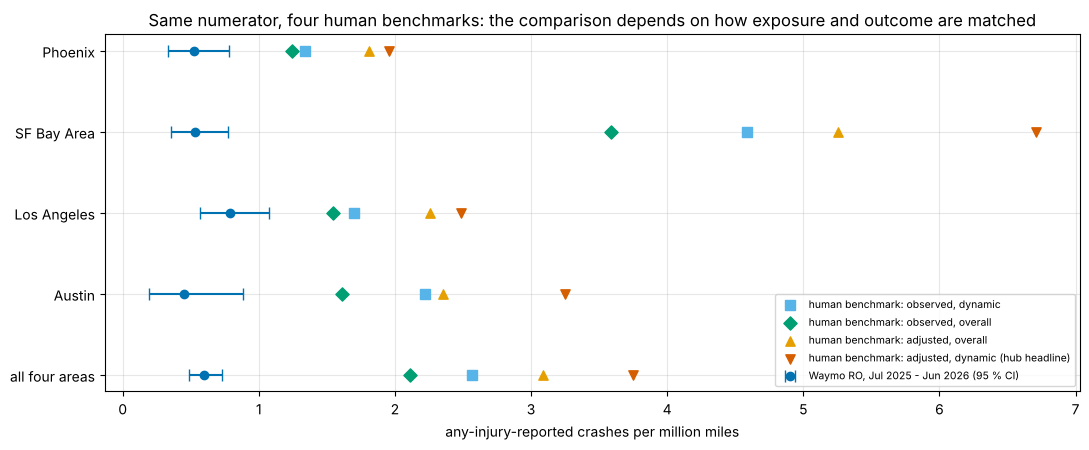

variant,Waymo rate,Waymo 95% upper,"observed, dynamic","observed, overall","adjusted, overall","adjusted, dynamic (hub headline)"
area,,,,,,
Austin,0.45,0.88,2.22,1.61,2.35,3.25
Los Angeles,0.79,1.08,1.70,1.54,2.26,2.49
Phoenix,0.52,0.78,1.34,1.24,1.81,1.95
SF Bay Area,0.53,0.77,4.58,3.59,5.25,6.71
all four areas,0.60,0.73,2.57,2.11,3.09,3.75


In [16]:
BENCH_AREA = {"Maricopa": "Phoenix", "San Francisco Bay Area": "SF Bay Area", "Los Angeles": "Los Angeles", "Travis": "Austin"}
VARIANTS = {"Any-injury-reported (Observed, Dynamic)": "observed, dynamic",
            "Any-injury-reported (observed, non-Dynamic)": "observed, overall",
            "Any-injury-reported (non-Dynamic)": "adjusted, overall",
            "Any-injury-reported": "adjusted, dynamic (hub headline)"}
b = hub_bench[(hub_bench["Grouping Type"] == "All Crashes") & hub_bench["Benchmark Comparison"].isin(VARIANTS)
              & hub_bench["County Name"].isin(BENCH_AREA)]
bench = b.assign(area=b["County Name"].map(BENCH_AREA), variant=b["Benchmark Comparison"].map(VARIANTS)) \
         .pivot(index="area", columns="variant", values="Benchmark IPMM")[list(VARIANTS.values())]
w = ro_window[bench.index]
bench.loc["all four areas"] = (bench.mul(w, axis=0).sum() / w.sum())          # mileage-blended over OUR window
inj = rates[rates["outcome"] == "any-injury-reported"].set_index("area")

fig, ax = plt.subplots(figsize=(11, 4.6))
order = list(RO_MILES_CUM.columns) + ["all four areas"]
y = np.arange(len(order))
r = inj.loc[order]
ax.errorbar(r["rate per M miles"], y, xerr=[r["rate per M miles"] - r["95% CI low"], r["95% CI high"] - r["rate per M miles"]],
            fmt="o", color=OI["blue"], capsize=4, label="Waymo RO, Jul 2025 - Jun 2026 (95 % CI)")
markers = {"observed, dynamic": ("s", OI["sky"]), "observed, overall": ("D", OI["green"]),
           "adjusted, overall": ("^", OI["orange"]), "adjusted, dynamic (hub headline)": ("v", OI["red"])}
for v, (mk, col) in markers.items():
    ax.scatter(bench.loc[order, v], y, marker=mk, color=col, s=45, label=f"human benchmark: {v}", zorder=3)
ax.set_yticks(y, order); ax.invert_yaxis()
ax.set_xlabel("any-injury-reported crashes per million miles")
ax.set_title("Same numerator, four human benchmarks: the comparison depends on how exposure and outcome are matched")
ax.legend(fontsize=7.5, loc="lower right"); plt.tight_layout(); plt.show()

tab = bench.copy()
tab.insert(0, "Waymo rate", inj.loc[bench.index, "rate per M miles"])
tab.insert(1, "Waymo 95% upper", inj.loc[bench.index, "95% CI high"])
display(tab.round(2))

In [17]:
allr = tab.loc["all four areas"]
print("Text summary (computed):")
print(f"- Waymo RO any-injury-reported rate, Jul 2025 - Jun 2026, four areas: {allr['Waymo rate']:.2f} per M miles "
      f"(95 % upper bound {allr['Waymo 95% upper']:.2f}).")
for v in VARIANTS.values():
    red_point = 100 * (1 - allr["Waymo rate"] / allr[v])
    red_conservative = 100 * (1 - allr["Waymo 95% upper"] / allr[v])
    print(f"- vs {v:34s} {allr[v]:.2f}: reduction {red_point:4.0f} % (at least {red_conservative:4.0f} % using the upper bound)")
spread = bench.loc[list(BENCH_AREA.values()), "adjusted, dynamic (hub headline)"]
print(f"- Human benchmarks differ by area by a factor of {spread.max() / spread.min():.1f} "
      f"({spread.idxmin()} {spread.min():.2f} to {spread.idxmax()} {spread.max():.2f}): a fleet that shifts mileage between")
print("  cities changes its 'average' rate without any change in driving behaviour. Compare like with like, area by area.")

Text summary (computed):
- Waymo RO any-injury-reported rate, Jul 2025 - Jun 2026, four areas: 0.60 per M miles (95 % upper bound 0.73).
- vs observed, dynamic                  2.57: reduction   77 % (at least   72 % using the upper bound)
- vs observed, overall                  2.11: reduction   72 % (at least   65 % using the upper bound)
- vs adjusted, overall                  3.09: reduction   81 % (at least   76 % using the upper bound)
- vs adjusted, dynamic (hub headline)   3.75: reduction   84 % (at least   81 % using the upper bound)
- Human benchmarks differ by area by a factor of 3.4 (Phoenix 1.95 to SF Bay Area 6.71): a fleet that shifts mileage between
  cities changes its 'average' rate without any change in driving behaviour. Compare like with like, area by area.


**Reading the result.** The point estimates differ by benchmark choice by tens of percentage points, while the statistical uncertainty of Waymo's own rate (with about 170 million miles) is comparatively small. At this scale, **the systematic questions dominate the random error**: which crashes count, which human population is the reference, and whether under-reporting is corrected. This is why the RAVE checklist (Scanlon et al., 2025) asks retrospective AV safety studies to document exactly these choices. Other operators publish less: for the other ADS operators in the file we found no published per-area exposure in a form that can be matched to their SGO reports (as of October 2026), so no rate can be computed for them from public data.

Note also what the rates do not show: crashes per mile on urban streets say little about freeway operation, night-time, or rare severe outcomes — see the exposure arithmetic in [06 · Industry deployment](06_industry_deployment.ipynb) and [06-08 · Statistical safety validation](../06_AI_Safety_ISO_PAS_8800/08_statistical_safety_validation.ipynb).

---
## 6. Safety performance indicators and a monitoring dashboard

UL 4600 requires **safety performance indicators** to keep a deployed system's safety case valid: an SPI is a metric with a **threshold** whose violation puts a safety-case claim in doubt and triggers a defined response (Ratiu et al., 2024; see [notebook 01](01_odd_and_runtime_monitoring.ipynb)).

- **Lagging** indicators count harm (injury crashes, air-bag deployments, VRU crashes). They are what matters, but rare events give wide intervals per quarter.
- **Leading** indicators measure precursors or the health of safety mechanisms: here, crashes where the AV was moving and its **front** made contact (a proxy for AV-initiated conflicts), and low-speed manoeuvre crashes (backing, parking). Inside a company the leading set is much richer (near misses from on-board data, hard-braking events, remote-assistance requests, ODD exits, monitor false alarms) — none of which is public.
- A metric **without** a threshold and response is a *monitored quantity*, not an SPI; the struck-while-stopped rate is shown as such.

Quarterly values for the four areas, joining Waymo's RO crash list to the SGO fields by report ID.

> **Illustrative thresholds:** the thresholds below are chosen for teaching (e.g. "injury crash rate at most 50 % of the matched human benchmark"). In a real safety case they are derived from the claims and the risk-acceptance criteria.

In [18]:
sgo_fields = reports["ADS"].set_index("Report ID")[["SV Pre-Crash Movement", "SV Contact Area - Front", "vru",
                                                      "sv_moving", "Within ODD?"]]
q = hc.join(sgo_fields, on="SGO Report ID")
print(f"RO crashes in the four areas: {len(q)}; matched to SGO fields: {int(q['sv_moving'].notna().sum())}")
q["front contact while moving"] = q["sv_moving"].astype("boolean").fillna(False) & q["SV Contact Area - Front"].eq("Y")
q["backing or parking manoeuvre"] = q["SV Pre-Crash Movement"].isin(["Backing", "Parking Maneuver"])
q["struck while stopped/parked"] = q["SV Pre-Crash Movement"].isin(["Stopped", "Parked"])
q["VRU crash"] = q["vru"].astype("boolean").fillna(False) | q["Crash Type"].isin(["Pedestrian", "Cyclist"])
q["injury"] = q["Is Any-Injury-Reported"].astype(bool)
q["air bag"] = q["Is Any Vehicle Airbag Deployment"].astype(bool)

blend = lambda v: float((bench.loc[list(BENCH_AREA.values()), v] * ro_window[list(BENCH_AREA.values())]).sum()
                        / ro_window[list(BENCH_AREA.values())].sum())
air_b = hub_bench[(hub_bench["Grouping Type"] == "All Crashes") & (hub_bench["Benchmark Comparison"] == "Any Airbag Deployment")
                  & hub_bench["County Name"].isin(BENCH_AREA)].set_index("County Name")["Benchmark IPMM"].rename(BENCH_AREA)
air_blend = float((air_b * ro_window[air_b.index]).sum() / ro_window[air_b.index].sum())
SPIS = [  # (column, title, kind, threshold per M miles or None, claim)
    ("injury", "Any-injury-reported crashes", "lagging", 0.5 * blend("adjusted, dynamic (hub headline)"),
     "<= 50 % of matched human benchmark"),
    ("air bag", "Air-bag deployment crashes", "lagging", 0.5 * air_blend, "<= 50 % of matched human benchmark"),
    ("VRU crash", "Crashes with a VRU", "lagging", 0.10, "illustrative: <= 0.10 per M miles"),
    ("front contact while moving", "Front contact while AV moving", "leading", 1.0, "illustrative: <= 1.0 per M miles"),
    ("backing or parking manoeuvre", "Backing / parking manoeuvre crashes", "leading", 0.15, "illustrative: <= 0.15 per M miles"),
    ("struck while stopped/parked", "Struck while stopped or parked", "monitored", None, "no threshold: context only"),
]
qt = ["Q3 2025", "Q4 2025", "Q1 2026", "Q2 2026"]
spi_rows = []
for col, title, kind, thr, claim in SPIS:
    for quarter in qt + ["12 months"]:
        sub = q if quarter == "12 months" else q[q["quarter"] == quarter]
        miles = ro_window["all four areas"] if quarter == "12 months" else ro_q.loc[quarter, "all four areas"]
        k = int(sub[col].sum()); lo, hi = poisson_rate_interval(k, miles)
        if thr is None:
            status = "monitored"
        elif hi <= thr:
            status = "met"
        elif lo > thr:
            status = "violated"
        else:
            status = "inconclusive"
        spi_rows.append({"SPI": title, "type": kind, "period": quarter, "events": k, "miles [M]": round(miles, 2),
                         "rate": k / miles, "low": lo, "high": hi, "threshold": thr, "claim": claim, "status": status})
spi = pd.DataFrame(spi_rows)
display(spi[spi["period"] == "12 months"].drop(columns=["period"]).round(3))

RO crashes in the four areas: 916; matched to SGO fields: 915


,SPI,type,events,miles [M],rate,low,high,threshold,claim,status
4,Any-injury-reported crashes,lagging,100,166.74,0.600,0.488,0.729,1.876,<= 50 % of matched human benchmark,met
9,Air-bag deployment crashes,lagging,46,166.74,0.276,0.202,0.368,0.797,<= 50 % of matched human benchmark,met
14,Crashes with a VRU,lagging,11,166.74,0.066,0.033,0.118,0.100,illustrative: <= 0.10 per M miles,inconclusive
19,Front contact while AV moving,leading,52,166.74,0.312,0.233,0.409,1.000,illustrative: <= 1.0 per M miles,met
24,Backing / parking manoeuvre crashes,leading,12,166.74,0.072,0.037,0.126,0.150,illustrative: <= 0.15 per M miles,met
29,Struck while stopped or parked,monitored,535,166.74,3.209,2.942,3.492,NaN,no threshold: context only,monitored


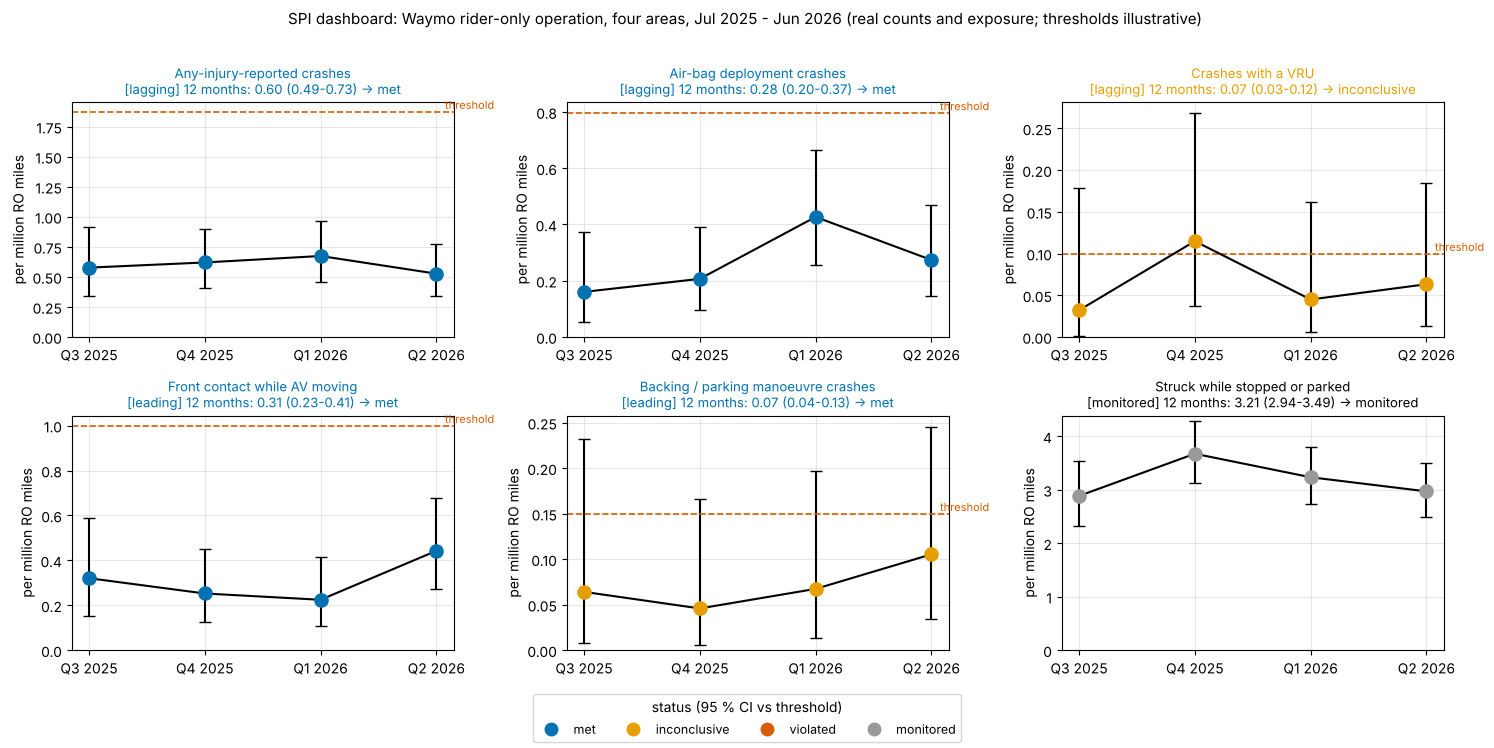

In [19]:
STATUS_COL = {"met": OI["blue"], "inconclusive": OI["orange"], "violated": OI["red"], "monitored": OI["grey"]}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, title, kind, thr, claim) in zip(axes.flat, SPIS):
    s = spi[(spi["SPI"] == title) & (spi["period"] != "12 months")]
    x = np.arange(len(s))
    ax.errorbar(x, s["rate"], yerr=[s["rate"] - s["low"], s["high"] - s["rate"]], fmt="o-", color=OI["black"], capsize=4)
    for xi, (_, r) in zip(x, s.iterrows()):
        ax.scatter(xi, r["rate"], s=90, color=STATUS_COL[r["status"]], zorder=3)
    if thr is not None:
        ax.axhline(thr, color=OI["red"], ls="--", lw=1.2)
        ax.text(len(s) - 0.5, thr, " threshold", color=OI["red"], fontsize=8, va="bottom", ha="right")
    year = spi[(spi["SPI"] == title) & (spi["period"] == "12 months")].iloc[0]
    ax.set_title(f"{title}\n[{kind}] 12 months: {year['rate']:.2f} ({year['low']:.2f}-{year['high']:.2f}) -> {year['status']}",
                 fontsize=9.5, color=STATUS_COL[year["status"]] if year["status"] != "monitored" else OI["black"])
    ax.set_xticks(x, s["period"]); ax.set_ylabel("per million RO miles"); ax.set_ylim(bottom=0)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=l) for l, c in STATUS_COL.items()]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=9, title="status (95 % CI vs threshold)")
fig.suptitle("SPI dashboard: Waymo rider-only operation, four areas, Jul 2025 - Jun 2026 (real counts and exposure; "
             "thresholds illustrative)", fontsize=11)
plt.tight_layout(rect=(0, 0.07, 1, 0.97)); plt.show()

In [20]:
print("Text summary (computed from the SPI table):")
for _, r in spi[spi["period"] == "12 months"].iterrows():
    thr = "no threshold" if r["threshold"] is None or pd.isna(r["threshold"]) else f"threshold {r['threshold']:.2f}"
    print(f"- {r['SPI']} ({r['type']}): {r['events']} events, {r['rate']:.2f} per M miles "
          f"(95 % CI {r['low']:.2f}-{r['high']:.2f}); {thr} -> {r['status']}")
inc = spi[(spi["status"] == "inconclusive") & (spi["period"] != "12 months")]
print(f"{len(inc)} quarterly values are inconclusive: the interval straddles the threshold. With rare events, a quarter")
print("is often too short to decide; the response rule must say what happens then (e.g. pool quarters, investigate early).")

Text summary (computed from the SPI table):
- Any-injury-reported crashes (lagging): 100 events, 0.60 per M miles (95 % CI 0.49-0.73); threshold 1.88 -> met
- Air-bag deployment crashes (lagging): 46 events, 0.28 per M miles (95 % CI 0.20-0.37); threshold 0.80 -> met
- Crashes with a VRU (lagging): 11 events, 0.07 per M miles (95 % CI 0.03-0.12); threshold 0.10 -> inconclusive
- Front contact while AV moving (leading): 52 events, 0.31 per M miles (95 % CI 0.23-0.41); threshold 1.00 -> met
- Backing / parking manoeuvre crashes (leading): 12 events, 0.07 per M miles (95 % CI 0.04-0.13); threshold 0.15 -> met
- Struck while stopped or parked (monitored): 535 events, 3.21 per M miles (95 % CI 2.94-3.49); no threshold -> monitored
8 quarterly values are inconclusive: the interval straddles the threshold. With rare events, a quarter
is often too short to decide; the response rule must say what happens then (e.g. pool quarters, investigate early).


**How a dashboard like this is used.** Each tile belongs to a claim in the safety case. A *met* status supports the claim for the period; *inconclusive* means more exposure is needed or the claim must be argued with other evidence; *violated* triggers the escalation process of Section 9. The lagging tiles are what regulators and the public see; the leading tiles are where an engineering team can act before harm accumulates — and they are only as good as the internal data behind them (near misses, disengagements, remote-assistance logs), which no public dataset contains.

---
## 7. Narrative text analysis

The narrative is the richest field — and the most redacted. Where it is not redacted, simple keyword themes already show what kinds of crashes dominate. Keyword matching is crude (a "rear" can be the AV's rear or the other vehicle's), so every theme must be **validated by reading samples** before it is used.

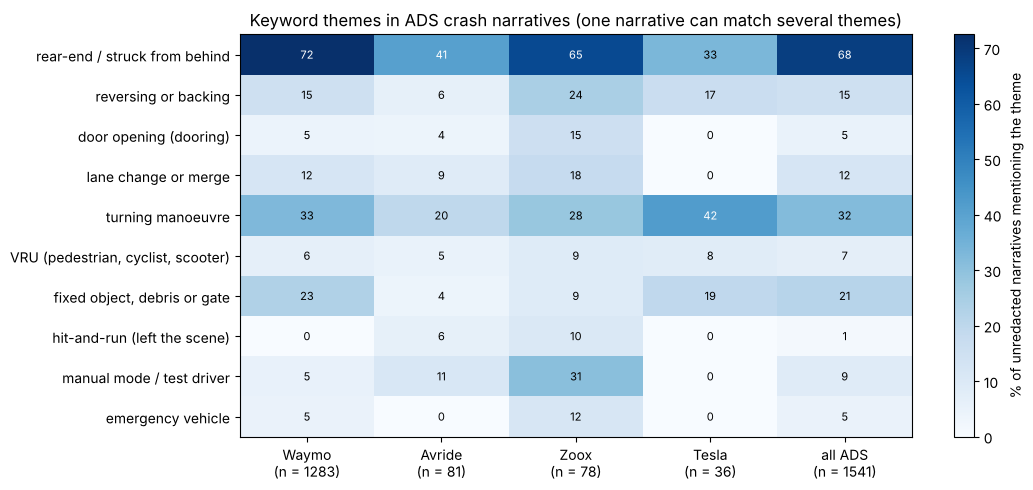

Unredacted ADS narratives: 1541 of 1551 reports. Unredacted ADAS narratives: 214 of 2427 - too few, and too selective, for a theme analysis of Level 2 crashes.


In [21]:
THEMES = {
    "rear-end / struck from behind": r"\brear\b|from behind",
    "reversing or backing": r"\brevers|\bback(?:ed|ing)\b",
    "door opening (dooring)": r"\bdoor\b",
    "lane change or merge": r"chang(?:e|ed|ing) lanes?|merg",
    "turning manoeuvre": r"\b(?:left|right)[- ]turn|\bturning\b",
    "VRU (pedestrian, cyclist, scooter)": r"pedestrian|cyclist|bicycl|scooter|skateboard|motorcycl",
    "fixed object, debris or gate": r"debris|\bpole\b|\bgate\b|\bcurb\b|bollard|cone|fixed object",
    "hit-and-run (left the scene)": r"left the scene|did not stop|fled",
    "manual mode / test driver": r"manual mode|test driver|safety (?:driver|operator)|vehicle operator",
    "emergency vehicle": r"ambulance|fire truck|police vehicle|emergency vehicle|first responder",
}
nar = reports["ADS"][~reports["ADS"]["narrative_cbi"] & reports["ADS"]["Narrative"].notna()].copy()
nar["text"] = nar["Narrative"].str.lower()
for theme, pat in THEMES.items():
    nar[theme] = nar["text"].str.contains(pat, regex=True)
big = nar["operator"].value_counts().index[:4]
theme_share = pd.DataFrame({op: 100 * nar.loc[nar["operator"] == op, list(THEMES)].mean() for op in big})
theme_share["all ADS"] = 100 * nar[list(THEMES)].mean()
counts = nar["operator"].value_counts()[big]

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(theme_share.values, cmap="Blues", aspect="auto", vmin=0, vmax=max(60, theme_share.values.max()))
ax.set_xticks(range(theme_share.shape[1]), [f"{c}\n(n = {counts.get(c, len(nar))})" for c in theme_share.columns])
ax.set_yticks(range(len(THEMES)), list(THEMES)); ax.grid(False)
for i in range(theme_share.shape[0]):
    for j in range(theme_share.shape[1]):
        v = theme_share.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 40 else "black")
fig.colorbar(im, ax=ax, label="% of unredacted narratives mentioning the theme")
ax.set_title("Keyword themes in ADS crash narratives (one narrative can match several themes)")
plt.tight_layout(); plt.show()
print(f"Unredacted ADS narratives: {len(nar)} of {len(reports['ADS'])} reports. "
      f"Unredacted ADAS narratives: {int((~reports['ADAS']['narrative_cbi']).sum())} of {len(reports['ADAS'])} "
      "- too few, and too selective, for a theme analysis of Level 2 crashes.")

In [22]:
# Validate a theme by reading samples (seeded, so the same examples appear each run).
theme = "door opening (dooring)"
sample = nar[nar[theme]].sample(n=min(2, int(nar[theme].sum())), random_state=7)
for _, r in sample.iterrows():
    text = re.sub(r"\s+", " ", r["Narrative"])
    i = max(0, text.lower().find("door") - 220)
    print(f"[{r['operator']}, {r['Incident Date']}] ...{text[i:i + 420]}...\n")
print(f"Theme '{theme}': {int(nar[theme].sum())} narratives. Reading them shows whether 'door' means a passenger opening")
print("a door into traffic, another vehicle's door, or a garage door - the keyword alone cannot tell.")

[Waymo, AUG-2025] ... maneuvering between the Waymo AV and a passenger car stopped in the right lane. As the motorcycle passed between the Waymo AV and the stationary passenger car, a passenger in the passenger car opened the rear left side door and the motorcycle made contact with the open rear left side door of the passenger car. As the motorcycle fell to the left, the motorcycle made contact with the right side of the stationary Waymo...

[Waymo, JUN-2025] ...acing east for a passenger pick-up on [XXX] adjacent to a parking lot at [XXX]. A passenger entered the Waymo AV and the Waymo AV began to proceed forward momentarily before the passenger opened the front passenger side door and exited the Waymo AV, prompting the Waymo AV to stop. The passenger then re-entered the Waymo AV and the Waymo AV proceeded to pass to the left of a different Waymo AV stopped facing east on [...

Theme 'door opening (dooring)': 75 narratives. Reading them shows whether 'door' means a passenger opening
a

Narratives are written by the reporting entity, in its own style (Waymo's are templated and detailed; others are brief), so theme frequencies partly reflect **writing conventions**. For engineering use, themes become hypotheses — e.g. "a share of crashes involve passengers opening doors into cyclists" — that are then checked against the operator's own logs and fed into the SOTIF triggering-condition analysis ([04-02](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb)).

---
## 8. Limitations and biases

| Bias | Mechanism in SGO data | Effect | Mitigation |
|---|---|---|---|
| **Notice bias** | Level 2 reports depend on what the manufacturer learns (telematics, claims, media) | connected fleets report more; counts measure data access | compare only within a manufacturer over time; use the "source" fields |
| **Threshold differences** | ADS: nearly all contacts; ADAS: severe only; thresholds changed in June 2025 | ADS and ADAS counts not comparable; trend breaks at amendments | analyse one amendment period; filter to common criteria |
| **No exposure** | miles, hours, road types not reported | counts track fleet growth | use dated operator exposure, matched filters |
| **Benchmark mismatch** | human data: police-reported, under-reported, different roads/areas | biased reductions | area-matched, outcome-matched, dynamic benchmarks; report variants |
| **No fault** | definition includes being struck; allegations | crash count ≠ ADS error count | narratives, crash types, independent investigation |
| **Redaction** | CBI claims on narratives, ODD, software version | text analysis impossible for some makers | request data via regulators; analyse redaction itself |
| **Reporting lag and revisions** | monthly reports, updates, corrections (e.g. NHTSA corrected a narrative in Aug 2026) | recent months undercounted; numbers change | mark incomplete months; pin the data release |
| **Small numbers** | serious and fatal outcomes are rare | wide intervals | exact Poisson CIs; leading indicators |
| **Selection by deployment** | operators choose cities, roads and times | results do not transfer to other ODDs | state the ODD of every rate |

---
## 9. Field monitoring obligations and incident escalation

Field monitoring is no longer optional for automated driving. The main obligations (as of October 2026):

| Source | Field-monitoring requirement |
|---|---|
| **UN R157** (ALKS), Annex 4 §3.5.4 | processes "to monitor safety-relevant incidents/crashes/collisions caused by the engaged" system and "to manage potential safety-relevant gaps post-registration (closed loop of field monitoring) and to update the vehicles"; critical incidents are reported to the type-approval authority |
| **UN R155** (cybersecurity), §7.2.2.2(g), §7.4.1 | CSMS processes to monitor for, detect and respond to cyber-attacks, threats and vulnerabilities on vehicles in the field; monitoring outcomes reported to the approval authority at least once a year |
| **Regulation (EU) 2022/1426** (ADS of fully automated vehicles), Annex III Part 5 | in-service monitoring and reporting: safety-critical occurrences notified **without delay**; listed short-term occurrences **within one month**; an **annual** report showing that field results are consistent with the pre-market safety assessment, aggregated per hour or per kilometre of ADS operation |
| **ISO/TS 5083:2025** | safety activities continue after deployment: field data feed back into the safety argument |
| **UL 4600** (3rd ed., 2023) | SPIs with thresholds and defined responses keep the safety case valid in operation |
| **NHTSA SGO 2021-01** (US) | crash reports within 5 calendar days (severe) or monthly (other ADS crashes), Section 1 |
| **49 CFR Part 573** (US) | a defect or non-compliance determination leads to a recall report within five working days |

These requirements all assume the same internal loop. The cell below applies a simple triage rule — modelled on the SGO criteria and the EU "safety-critical" category — to the real ADS reports, to show how much load each escalation tier would carry.

In [23]:
def triage(r) -> str:
    # Escalation tier for one crash report (teaching rule, not a regulatory classification).
    if r["Highest Injury Severity Alleged"] in ("Fatality", "Serious W/ Hospitalization", "Serious W/O Hospitalization") or r["vru"]:
        return "T1 safety-critical: immediate review, regulator within days"
    if r["hospital_or_fatal"] or r["airbag"] or r["towed"]:
        return "T2 severe: 5-day report, engineering review this week"
    if r["sv_moving"] and r["SV Contact Area - Front"] == "Y":
        return "T3 AV-initiated contact: root-cause review, SPI update"
    return "T4 other: monthly report, trend monitoring"


tiers = crashes["ADS"].apply(triage, axis=1).value_counts().sort_index()
display(tiers.to_frame("ADS crashes (third-amendment period)"))
weeks = (last_release - pd.Timestamp("2025-06-16")).days / 7      # amendment in force until the last report received
print(f"Average load: {tiers.iloc[0] / weeks:.1f} T1 and {tiers.iloc[1] / weeks:.1f} T2 cases per week across all operators "
      f"(16 Jun 2025 to the last report received, about {weeks:.0f} weeks).")

,ADS crashes (third-amendment period)
"T1 safety-critical: immediate review, regulator within days",30
"T2 severe: 5-day report, engineering review this week",778
"T3 AV-initiated contact: root-cause review, SPI update",53
"T4 other: monthly report, trend monitoring",689


Average load: 0.5 T1 and 12.3 T2 cases per week across all operators (16 Jun 2025 to the last report received, about 63 weeks).


In [24]:
# Safety-case evidence (see 08-06): record the values computed above for safety_case/aeb_pedestrian.yaml.
from avsafety.assurance import record_evidence
record_evidence(
    "field-spi-waymo", notebook="07_Runtime_Assurance_and_Operations/05_field_safety_monitoring.ipynb",
    title="SPIs, Waymo rider-only operation in four areas, 12 months",
    dataset="NHTSA SGO 2021-01 ADS reports; Waymo Safety Impact Data Hub (data through June 2026)",
    licence="NHTSA: public US government data; Waymo hub: published for research and reproduction",
    data_until="2026-06-30", confidence=0.95, units={"injury_high": "per 10^6 RO miles", "vru_high": "per 10^6 RO miles"},
    exposure_million_miles=ro_window["all four areas"],
    **{f"{key}_{col}": spi.set_index(["SPI", "period"]).loc[(name, "12 months"), src]
       for key, name in [("injury", "Any-injury-reported crashes"), ("vru", "Crashes with a VRU")]
       for col, src in [("events", "events"), ("rate", "rate"), ("low", "low"), ("high", "high"), ("threshold", "threshold")]})

Evidence field-spi-waymo: exposure_million_miles=166.739, injury_events=100, injury_rate=0.59974, injury_low=0.487972, injury_high=0.729444, injury_threshold=1.87588 -> safety_case/evidence/field-spi-waymo.json

**Escalation process** (one common structure; names differ between companies):

1. **Detect** — on-board event triggers, remote-assistance logs, customer reports, police or media; for third-party notice, the clock of the SGO starts at *notice*, not at verification.
2. **Triage** within hours — tier as above; preserve data (logs, video, DSSAD / EDR data); decide on immediate operational measures (pause a route, restrict the ODD, ground a software release).
3. **Report** — regulator deadlines run in parallel to the investigation (SGO 5 days; EU ADS "without delay"; R157 critical incidents). Reports must be complete and consistent: incomplete disclosure was a central finding in the Cruise case ([02-01](../02_Failures_and_Robustness/01_incident_case_studies.ipynb)).
4. **Investigate** — reconstruct the scenario, separate ADS contribution from other road users, classify (E/E fault → ISO 26262; functional insufficiency or triggering condition → ISO 21448; ML insufficiency → ISO/PAS 8800; attack → ISO/SAE 21434).
5. **Decide and act** — software fix and regression tests, ODD restriction, recall where a safety defect is determined (Part 573 in the US).
6. **Close the loop** — update HARA/SOTIF analyses, scenario catalogue, SPIs and the safety case; check the fix in the field with the same SPIs.

---
## In industry

**Work products.** Field monitoring feeds the **SPI dashboard and safety-case maintenance** (UL 4600), the **in-service monitoring and reporting** file for type approval (EU 2022/1426 Annex III; R157 Annex 4), the CSMS monitoring report (R155), the **regulatory crash reports** (SGO) and, when needed, the **recall decision record**. Its findings flow back into HARA, SOTIF triggering-condition analysis and the scenario database.

**Roles.** A field-safety or *safety operations* team owns triage and the dashboard; a **safety data analyst** owns exposure, benchmarks and statistics; regulatory affairs and legal own the reports; a product-safety committee decides on field actions; the safety-case owner updates the argument.

**What reviewers and assessors look for:**

- [ ] numerator and denominator filtered by the same rule (operation mode, area, period), and the filter documented;
- [ ] exposure sources dated and versioned; data releases pinned; incomplete periods marked;
- [ ] benchmark matched by geography, road type and outcome definition, with sensitivity to benchmark choice shown;
- [ ] confidence intervals, not point estimates, compared with thresholds; an explicit rule for inconclusive results;
- [ ] each SPI linked to a safety-case claim, a threshold and a response; leading indicators present, not only lagging ones;
- [ ] duplicate reports and report versions resolved; redaction and missing-data rates reported;
- [ ] escalation tiers with time limits that meet every applicable reporting deadline; evidence of closed loops (fix verified in the field).

The course website's [field-safety observatory](https://milinpatel07.github.io/Autonomous-Driving_AI-Safety-and-Security/observatory) applies the same cleaning (latest report version, one crash per `Same Incident ID`, matched exposure) to every monthly NHTSA release and marks the reporting-rule changes on the time axis.

## Key takeaways

1. The SGO (third amendment, effective 16 June 2025) requires five-day reports for crashes with a fatality, hospital transport, air-bag deployment or VRU strike — plus tow-away for ADS — and monthly reports for other ADS crashes with property damage; Level 2 ADAS reports only the severe category.
2. Reports are not crashes and crashes are not rates: resolve versions and `Same Incident ID`, and never rank operators by counts.
3. ADS and ADAS files can be compared only on composition within the common severe subset, and even then notice and redaction biases dominate.
4. Rates need exposure that matches the numerator's filter: Waymo's rider-only crash list excludes the SGO reports with a human operator on board.
5. With hundreds of millions of miles, the choice of human benchmark (area, dynamic weighting, under-reporting correction) moves the result more than the random error does.
6. An SPI is a metric with a threshold, a claim and a response; leading indicators are needed because lagging outcomes are rare.
7. Narrative themes are hypotheses that must be validated by reading; redaction can make text analysis impossible.
8. UN R157, UN R155, EU 2022/1426, ISO/TS 5083 and UL 4600 all require a closed field-monitoring loop; a tiered escalation process has to meet every reporting deadline in parallel with the investigation.

## Self-assessment

1. Which crashes must an ADS operator report within five days under the third amended SGO, and which additional crashes monthly? What differs for Level 2 ADAS?
2. Why do the ADS file's crash counts by operator not show which operator is safer?
3. A colleague divides all Waymo SGO reports in a year by Waymo's rider-only miles. What is wrong, and in which direction is the result biased?
4. Why can the same Waymo injury-crash rate correspond to a 70 % or an 82 % reduction?
5. A quarterly SPI value has a 95 % interval that contains the threshold. What status does it get, and what should the response rule say?
6. Name two biases that make Level 2 ADAS report counts unsuitable for comparing manufacturers.
7. What does EU 2022/1426 require the manufacturer to report, and on which time scales?

<details>
<summary>Answers</summary>

1. ADS: fatality, hospital transport, air-bag deployment, VRU strike or vehicle tow-away — within five calendar days of notice; other crashes with property damage (damage reasonably expected above USD 1,000, single-vehicle crashes, or crashes in which the ADS vehicle struck another vehicle or object) by the 15th of the following month. Level 2 ADAS: only fatality, hospital transport, air-bag deployment or VRU strike, within five days; no tow-away criterion and no monthly property-damage reports.
2. Counts scale with fleet size and miles driven, with notice and reporting practice, and include crashes caused by others; without exposure and matched filters they are not rates.
3. The numerator includes crashes with a human operator on board (testing, other cities), the denominator only rider-only miles; the rate is biased upwards. (The converse mismatch biases it downwards.)
4. The benchmarks differ: overall or dynamic (re-weighted to where the AV drives), and observed or corrected for under-reporting of human crashes; each yields a different human rate.
5. "Inconclusive". The rule must say what follows — e.g. pool with the next quarter, or open an investigation if the point estimate exceeds the threshold — rather than silently counting it as "met".
6. Notice bias (connected vehicles report more crashes via telematics), redaction of narratives and fields, different fleet sizes and road use without exposure, severe-only threshold.
7. Safety-critical occurrences without delay; specified short-term occurrences within one month; an annual report (aggregated per hour or per kilometre of ADS operation) showing that field results are consistent with the pre-market safety assessment, that performance requirements are met, and how new safety issues were addressed.
</details>

## References

**Regulation and data**
- NHTSA. *Standing General Order 2021-01: Incident Reporting for ADS and Level 2 ADAS* (third amendment, 24 April 2025, effective 16 June 2025). https://www.nhtsa.gov/laws-regulations/standing-general-order-crash-reporting
- NHTSA (2026). *Agency Information Collection Activities … Incident Reporting for ADS and Level 2 ADAS*. Federal Register 91 FR 30789, 26 May 2026. https://www.govinfo.gov/content/pkg/FR-2026-05-26/html/2026-10363.htm
- NHTSA (2026). *AV Framework Updates and Request for Comments on Interim Guidance*. Federal Register 91 FR 48485, 31 July 2026. https://www.federalregister.gov/documents/2026/07/31/2026-15483/av-framework-updates-and-request-for-comments-on-interim-guidance
- NHTSA (2026). *Standing General Order (SGO) 2021-01 Data Dictionary*, 15 October 2026. https://static.nhtsa.gov/odi/ffdd/sgo-2021-01/SGO-2021-01_Data_Element_Definitions.pdf
- Waymo. *Safety Impact Data Hub*, data through June 2026, and *Release Notes* (2 October 2026). https://waymo.com/safety/impact/
- UN Regulation No. 157 (ALKS), Annex 4 §3.5.4 (incl. 01 series of amendments).
- UN Regulation No. 155 (Cyber security and cyber security management system), §7.2.2.2 and §7.4.1.
- Commission Implementing Regulation (EU) 2022/1426 (type-approval of the ADS of fully automated vehicles), Annex III Part 5 (in-service monitoring and reporting). https://eur-lex.europa.eu/eli/reg_impl/2022/1426/oj
- 49 CFR Part 573, *Defect and noncompliance responsibility and reports*.
- ISO/TS 5083:2025. *Road vehicles — Safety for automated driving systems — Design, verification and validation*. https://www.iso.org/standard/81920.html
- UL 4600 (3rd ed., 2023). *Standard for Safety for the Evaluation of Autonomous Products*.

**Methods and benchmarks**
- Kusano, K. D., Scanlon, J. M., Chen, Y.-H., McMurry, T. L., Chen, R., Gode, T., Victor, T. (2024). Comparison of Waymo rider-only crash data to human benchmarks at 7.1 million miles. *Traffic Injury Prevention*, 25(sup1). https://doi.org/10.1080/15389588.2024.2380786
- Kusano, K. D., Scanlon, J. M., Chen, Y.-H., McMurry, T. L., Gode, T., Victor, T. (2025). Comparison of Waymo Rider-Only crash rates by crash type to human benchmarks at 56.7 million miles. *Traffic Injury Prevention*, 26(sup1). https://doi.org/10.1080/15389588.2025.2499887
- Scanlon, J. M., Teoh, E. R., Kidd, D. G., Kusano, K. D., Bärgman, J., et al. (2025). RAVE checklist: Recommendations for overcoming challenges in retrospective safety studies of automated driving systems. *Traffic Injury Prevention*, 26(5), 608–621. https://doi.org/10.1080/15389588.2024.2435620
- Chen, Y.-H., Scanlon, J. M., Kusano, K. D., McMurry, T. L., Victor, T. (2024). Dynamic Benchmarks: Spatial and Temporal Alignment for ADS Performance Evaluation. arXiv:2410.08903. https://arxiv.org/abs/2410.08903
- Blincoe, L., Miller, T., Wang, J.-S., Swedler, D., Coughlin, T., Lawrence, B., Guo, F., Klauer, S., Dingus, T. (2023). *The economic and societal impact of motor vehicle crashes, 2019 (Revised)*. NHTSA, DOT HS 813 403.
- Kalra, N., Paddock, S. M. (2016). Driving to safety: How many miles of driving would it take to demonstrate autonomous vehicle reliability? *Transportation Research Part A*, 94, 182–193. https://doi.org/10.1016/j.tra.2016.09.010
- Ratiu, D., Rohlinger, T., Stolte, T., Wagner, S. (2024). Towards an Argument Pattern for the Use of Safety Performance Indicators. SAFECOMP 2024 Workshops. arXiv:2410.00578. https://arxiv.org/abs/2410.00578

---
**Navigation:** ← [V2X and cooperative driving](04_v2x_cooperative_driving.ipynb) · [Module index](README.md) · [Industry deployment](06_industry_deployment.ipynb) →